# 05. CNN 평가와 가장 어려운 클래스 찾기
`05_evaluate.py`를 실행하여 학습·검증 결과, 혼동행렬, 클래스별 정답 수와 재현율을 기록합니다. 가장 어려운 클래스는 이번 검증 데이터에서 **재현율이 가장 낮은 클래스**로 정의합니다.

## 0. 작업 전 준비사항
PyTorch, torchvision, Pillow, pandas, matplotlib이 설치된 커널에서 **Run All**로 실행합니다. 기존 PNG 데이터와 작은 CNN을 CPU로 사용하며 다운로드는 필요하지 않습니다.

이 노트북은 실제 `05_evaluate.py`를 실행해 5 epoch 학습하고 검증 손실이 가장 낮은 모델을 복원합니다. 원본 스크립트는 `02_응용/outputs`에 CSV를 저장하고, 노트북은 같은 표와 그래프를 `02_응용/docs/outputs`에 저장합니다. 재실행하면 해당 결과 파일이 갱신됩니다.

In [1]:
%matplotlib inline
from pathlib import Path
import runpy
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
day_root = next((candidate for parent in (cwd, *cwd.parents)
                 for candidate in (parent / "20261102", parent)
                 if (candidate / "02_응용" / "05_evaluate.py").is_file()), None)
if day_root is None:
    raise FileNotFoundError("이 저장소 안에서 실행하세요.")
script_path = day_root / "02_응용" / "05_evaluate.py"
out = day_root / "02_응용" / "docs" / "outputs"
out.mkdir(parents=True, exist_ok=True)

## 1. 학습과 평가의 흐름
05번의 train·valid 데이터셋은 분리되어 있고, 두 데이터셋 모두 `Resize((32, 32)) → ToTensor()`를 적용합니다. 04번의 무작위 증강은 이 코드에서 사용하지 않습니다.

학습에서는 `model.train()` 상태에서 `zero_grad() → 순전파·손실 → backward() → step()` 순서로 가중치를 갱신합니다. 평가에서는 `model.eval()`과 `torch.no_grad()`를 사용하며 가중치를 갱신하지 않습니다.

각 epoch 말에 같은 시점의 모델로 train·valid 손실과 정확도를 측정합니다. 검증 손실이 최소인 epoch의 모델을 복원한 뒤 최종 혼동행렬을 계산하므로 마지막 epoch와 결과가 다를 수 있습니다. 이 검증 데이터는 모델 선택에도 사용되었으므로, 별도 test 데이터에서의 최종 성능과 구분합니다.

In [2]:
state = runpy.run_path(str(script_path))
history = pd.DataFrame(state["history"])
cm = state["cm"].numpy()
classes = state["train"].classes
metrics = state["class_metrics"].copy()
assert state["train"].class_to_idx == state["valid"].class_to_idx
assert cm.sum() == len(state["valid"])
assert int(np.trace(cm)) == int(metrics["correct"].sum())
assert (metrics["correct"] + metrics["incorrect"] == metrics["total"]).all()
print("클래스 번호:", dict(enumerate(classes)))
print("전체 검증 정확도:", f"{np.trace(cm) / cm.sum():.2%}")
history.to_csv(out / "evaluate_history.csv", index=False)
metrics.to_csv(out / "evaluate_class_metrics.csv", index=False)
pd.DataFrame(cm, index=classes, columns=classes).to_csv(out / "evaluate_confusion_matrix.csv")

 epoch  train_loss  train_accuracy  valid_loss  valid_accuracy
     1      0.6187          0.9167      0.6195            0.95
     2      0.6333          0.5000      0.6283            0.50
     3      0.3657          0.9833      0.3722            0.95
     4      0.1528          1.0000      0.1548            1.00
     5      0.0505          1.0000      0.0553            1.00
best epoch: 5
혼동행렬 행=실제, 열=예측:
 [[10, 0], [0, 10]]
클래스별 정답 수: [10, 10] / [10, 10]
클래스별 평가:
      class  correct  total  incorrect  recall
horizontal       10     10          0     1.0
  vertical       10     10          0     1.0
가장 어려운 클래스(최저 재현율): horizontal, vertical / 재현율: 100.00%
최저 재현율이 같아 단일 클래스로 구분할 수 없습니다.
클래스 번호: {0: 'horizontal', 1: 'vertical'}
전체 검증 정확도: 100.00%


## 2. 학습·검증 손실과 정확도
점선은 검증 손실이 가장 낮은 epoch입니다. 정확도는 맞힌 비율, 손실은 정답에 대한 예측 확신까지 반영하는 값이어서 두 지표의 변화가 항상 일치하지는 않습니다.

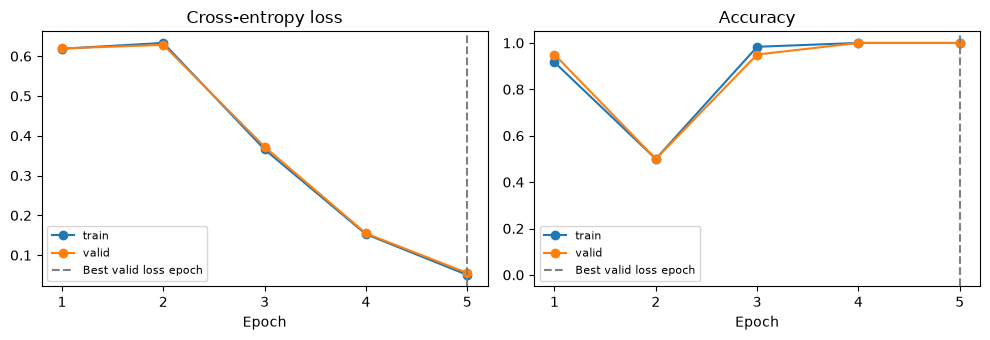

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Cross-entropy loss", "Accuracy"]):
    for phase in ["train", "valid"]:
        ax.plot(history["epoch"], history[f"{phase}_{metric}"], marker="o", label=phase)
    ax.axvline(state["best_epoch"], color="grey", linestyle="--", label="Best valid loss epoch")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_xticks(history["epoch"])
    ax.legend(fontsize=8)
axes[1].set_ylim(-0.05, 1.05)
fig.tight_layout()
fig.savefig(out / "evaluate_learning_curves.png", dpi=140)
plt.show()
plt.close(fig)

## 3. 혼동행렬 읽기
**행은 실제 클래스, 열은 예측 클래스**입니다. 대각선은 정답 수이고 나머지는 오답 수입니다. 예를 들어 행 `horizontal`, 열 `vertical`은 실제 가로 줄무늬를 세로로 예측한 수입니다.

왼쪽은 원래 개수, 오른쪽은 각 실제 클래스의 전체 표본 수로 나눈 비율입니다. 행 정규화 행렬의 대각선이 클래스별 재현율입니다. 검증 표본이 0인 행은 비율을 계산할 수 없어 N/A로 표시합니다.

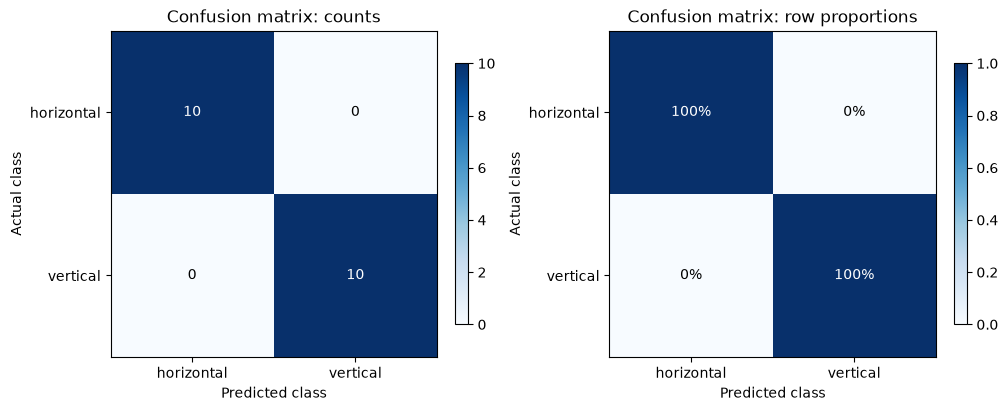

In [4]:
counts = cm.sum(axis=1)
normalized = np.divide(cm.astype(float), counts[:, None],
                       out=np.full(cm.shape, np.nan), where=counts[:, None] != 0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, values, title, ratio in zip(axes, [cm, normalized],
                                   ["Confusion matrix: counts", "Confusion matrix: row proportions"], [False, True]):
    im = ax.imshow(values, cmap="Blues", vmin=0, vmax=1 if ratio else max(1, cm.max()))
    for h in range(len(classes)):
        for w in range(len(classes)):
            value = values[h, w]
            text = "N/A" if np.isnan(value) else (f"{value:.0%}" if ratio else str(int(value)))
            ax.text(w, h, text, ha="center", va="center",
                    color="white" if value > (0.5 if ratio else max(1, cm.max()) / 2) else "black")
    ax.set_xticks(range(len(classes)), classes)
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(out / "evaluate_confusion_matrix.png", dpi=140)
plt.show()
plt.close(fig)

## 4. 클래스별 정답 수와 가장 어려운 클래스
클래스별 정답 수는 `cm.diag()`, 실제 클래스별 전체 수는 `cm.sum(1)`입니다.

**재현율 = 해당 실제 클래스의 정답 수 / 해당 실제 클래스의 전체 수**

단순 정답 수는 표본이 많은 클래스에 유리하므로, 가장 어려운 클래스는 재현율이 가장 낮은 클래스로 판단합니다. 최저 재현율이 같은 클래스는 모두 출력합니다. 모든 클래스가 만점이면 이번 표본에서 더 어려운 클래스를 구분할 수 없습니다. 검증 표본이 없는 클래스는 판단에서 제외합니다.

     class  correct  total  incorrect  recall
horizontal       10     10          0     1.0
  vertical       10     10          0     1.0
이번 검증에서 가장 어려운 클래스: horizontal, vertical
최저 재현율: 100.00%
동률이므로 하나의 클래스가 더 어렵다고 판단할 수 없습니다.
horizontal 오분류 대상: 없음
vertical 오분류 대상: 없음


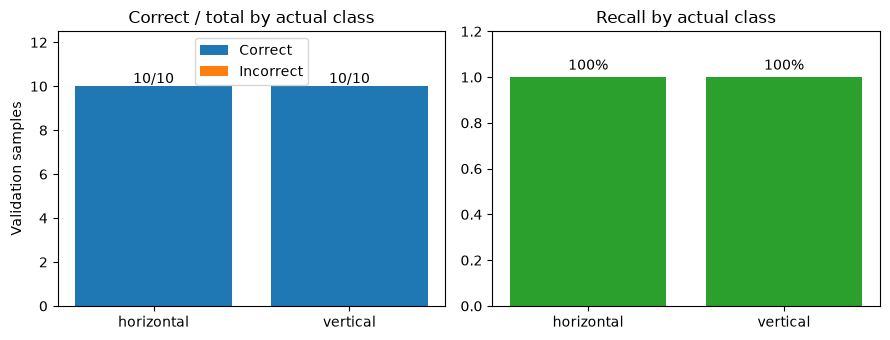

In [5]:
print(metrics.round(4).to_string(index=False))
evaluated = metrics.dropna(subset=["recall"])
if not evaluated.empty:
    lowest = evaluated["recall"].min()
    hardest = evaluated[evaluated["recall"] == lowest]
    print("이번 검증에서 가장 어려운 클래스:", ", ".join(hardest["class"]))
    print("최저 재현율:", f"{lowest:.2%}")
    if len(hardest) > 1:
        print("동률이므로 하나의 클래스가 더 어렵다고 판단할 수 없습니다.")
    for name in hardest["class"]:
        idx = classes.index(name)
        errors = [(classes[j], int(cm[idx, j])) for j in range(len(classes)) if j != idx and cm[idx, j] > 0]
        print(name, "오분류 대상:", errors if errors else "없음")
else:
    print("검증 표본이 없어 판단할 수 없습니다.")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(metrics["class"], metrics["correct"], label="Correct", color="tab:blue")
axes[0].bar(metrics["class"], metrics["incorrect"], bottom=metrics["correct"], label="Incorrect", color="tab:orange")
for i, row in metrics.iterrows():
    axes[0].text(i, row["total"] + 0.15, f"{row['correct']}/{row['total']}", ha="center")
axes[0].set_ylim(0, max(1, metrics["total"].max()) * 1.25)
axes[0].set_title("Correct / total by actual class")
axes[0].set_ylabel("Validation samples")
axes[0].legend()
bars = axes[1].bar(metrics["class"], metrics["recall"], color="tab:green")
axes[1].bar_label(bars, labels=[f"{v:.0%}" if pd.notna(v) else "N/A" for v in metrics["recall"]], padding=3)
axes[1].set_ylim(0, 1.2)
axes[1].set_title("Recall by actual class")
fig.tight_layout()
fig.savefig(out / "evaluate_class_results.png", dpi=140)
plt.show()
plt.close(fig)

## 5. 해석 시 확인할 점
이 결과는 seed=42, 5 epoch, 현재 학습·검증 데이터와 모델 설정에서의 결과입니다. 재현율이 낮은 클래스의 비대각선 셀을 보면 어떤 클래스로 혼동했는지 알 수 있습니다. 오분류 이미지의 줄무늬 방향, 대비, 노이즈를 직접 확인하면 원인을 탐색할 수 있지만 혼동행렬만으로 원인을 확정할 수는 없습니다.

검증 표본이 작으면 한 장의 오답도 비율을 크게 바꿀 수 있습니다. 동률일 때는 그대로 기록하고, 여러 seed나 추가 검증 표본에서 경향이 유지되는지 확인합니다. 개선 설정은 검증 데이터로 선택하고, 최종 성능은 따로 남겨둔 test 데이터로 평가합니다.